# Tarea 1 – Parte 1: Recolección y limpieza de noticias peruanas

**Pregunta guía:** ¿Pueden convertir titulares peruanos en un clasificador de noticias?

| Configuración | Valor |
| :--- | :--- |
| Fecha de descarga | **2026-10-18** (domingo) |
| Opción elegida | **B – El Comercio** (350–400 noticias, ~90–100 por categoría) |
| URL base | `https://elcomercio.pe` |
| Fuente de URLs | Sitemaps oficiales por sección, declarados en `robots.txt`: `https://elcomercio.pe/sitemap/web/{seccion}/?outputType=xml` para `politica`, `economia`, `deporte-total` y `tecnologia` |
| Fuente de titular, bajada y fecha | Página HTML de cada noticia (`requests` + `BeautifulSoup`) |
| Categorías finales | `politica`, `economia`, `deportes`, `ciencia_tecnologia` |

**¿Por qué sitemaps y no la portada de cada sección?**
Las portadas de sección de El Comercio cargan sus listados con JavaScript, y sus feeds RSS antiguos (`/arcio/rss/...`) redirigen o devuelven 404. En cambio, `robots.txt` publica los sitemaps de cada sección. Cada sitemap lista las ~100 notas más recientes con su URL y su fecha de modificación. Con esas URLs se visita cada nota una sola vez para leer el titular (`<h1>`), la bajada (`<h2>` del encabezado) y la fecha de publicación (`article:published_time`).

**Buenas prácticas aplicadas:** se revisa `robots.txt` antes de descargar, se usa un `User-Agent` descriptivo, hay una pausa de 1.5 s entre solicitudes y como máximo 1 reintento. Además, todo lo descargado se respalda en `datos/raw/`, así que al reejecutar el notebook no se vuelve a pedir lo que ya está guardado.

In [1]:
import json
import time
import urllib.robotparser
from datetime import date
from pathlib import Path
from urllib.parse import urlparse

import pandas as pd
import plotly.express as px
import plotly.io as pio
import requests
from bs4 import BeautifulSoup

# Plotly: interactivo en Jupyter/VS Code + copia PNG para que GitHub muestre los gráficos
pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].width = 900
pio.renderers["png"].height = 480
pd.set_option("display.max_colwidth", 120)

BASE = "https://elcomercio.pe"
MEDIO = "El Comercio"
USER_AGENT = "Mozilla/5.0 (compatible; TareaPUCP-DataSciencePython/1.0; uso academico; +https://github.com/IvettexMamani)"
PAUSA_SEG = 1.5          # pausa entre solicitudes
MAX_REINTENTOS = 1       # máximo 1 reintento por URL

DATOS = Path("datos")
RAW = DATOS / "raw"
(RAW / "sitemaps").mkdir(parents=True, exist_ok=True)

# Sección del sitemap -> categoría oficial esperada
SITEMAPS = {
    "politica": "politica",
    "economia": "economia",
    "deporte-total": "deportes",
    "tecnologia": "ciencia_tecnologia",
}
print("Fecha de ejecución:", date.today().isoformat())

Fecha de ejecución: 2026-10-18


## 1. Revisión de `robots.txt`
Se verifica que el `User-Agent` del proyecto pueda acceder a los sitemaps y a las páginas de noticias.

In [2]:
sesion = requests.Session()
sesion.headers.update({"User-Agent": USER_AGENT, "Accept-Language": "es-PE,es;q=0.9"})
_ultima = [0.0]

def descargar(url):
    # GET respetuoso: pausa mínima entre solicitudes y como máximo 1 reintento.
    for intento in range(MAX_REINTENTOS + 1):
        espera = PAUSA_SEG - (time.time() - _ultima[0])
        if espera > 0:
            time.sleep(espera)
        try:
            r = sesion.get(url, timeout=25)
            _ultima[0] = time.time()
            if r.status_code == 200:
                return r
            if r.status_code in (404, 410):
                return r                     # no tiene sentido reintentar
        except requests.RequestException as e:
            _ultima[0] = time.time()
            print(f"  error de red ({type(e).__name__}) en {url}")
    return None

r_robots = descargar(f"{BASE}/robots.txt")
if r_robots is not None and r_robots.status_code == 200:
    texto_robots = r_robots.text
    (RAW / "robots_elcomercio.txt").write_text(texto_robots, encoding="utf-8")
else:
    texto_robots = (RAW / "robots_elcomercio.txt").read_text(encoding="utf-8")
    print("robots.txt no respondió; se usa la copia guardada en datos/raw/")
rp = urllib.robotparser.RobotFileParser()
rp.parse(texto_robots.splitlines())

pruebas = [f"{BASE}/sitemap/web/{s}/?outputType=xml" for s in SITEMAPS] + [
    f"{BASE}/economia/ejemplo-noticia/", f"{BASE}/buscar/ejemplo/",
]
pd.DataFrame({"url": pruebas, "permitido": [rp.can_fetch(USER_AGENT, u) for u in pruebas]})

,url,permitido
0,https://elcomercio.pe/sitemap/web/politica/?outputType=xml,True
1,https://elcomercio.pe/sitemap/web/economia/?outputType=xml,True
2,https://elcomercio.pe/sitemap/web/deporte-total/?outputType=xml,True
3,https://elcomercio.pe/sitemap/web/tecnologia/?outputType=xml,True
4,https://elcomercio.pe/economia/ejemplo-noticia/,True
5,https://elcomercio.pe/buscar/ejemplo/,False


## 2. Extracción

### 2.1 Sitemaps por sección
Se descarga cada sitemap, se guarda el XML crudo en `datos/raw/sitemaps/` y se extraen las URLs con su fecha de modificación.

In [3]:
filas = []
for seccion, categoria in SITEMAPS.items():
    archivo = RAW / "sitemaps" / f"{seccion}.xml"
    if archivo.exists():
        xml = archivo.read_text(encoding="utf-8")
        origen = "respaldo local"
    else:
        r = descargar(f"{BASE}/sitemap/web/{seccion}/?outputType=xml")
        xml = r.text
        archivo.write_text(xml, encoding="utf-8")
        origen = "descargado"
    soup = BeautifulSoup(xml, "xml")
    urls = soup.find_all("url")
    for u in urls:
        filas.append({
            "sitemap": seccion,
            "categoria_sitemap": categoria,
            "url": u.loc.get_text(strip=True),
            "lastmod": u.lastmod.get_text(strip=True) if u.lastmod else None,
        })
    print(f"{seccion:<14} {len(urls):>4} URLs  ({origen})")

df_urls = pd.DataFrame(filas)
print("Total de URLs en sitemaps:", len(df_urls))
df_urls.head()

politica        100 URLs  (respaldo local)
economia        100 URLs  (respaldo local)
deporte-total   100 URLs  (respaldo local)
tecnologia      100 URLs  (respaldo local)
Total de URLs en sitemaps: 400


,sitemap,categoria_sitemap,url,lastmod
0,politica,politica,https://elcomercio.pe/politica/gobierno/jorge-nieto-dice-que-se-reunio-con-el-ejecutivo-aprobemos-los-20-puntos-y-ha...,2026-10-18T13:50:40-05:00
1,politica,politica,https://elcomercio.pe/politica/alvaro-vargas-llosa-eeuu-embajador-del-peru-en-estados-unidos-entrevista-noticia/,2026-10-18T11:50:00-05:00
2,politica,politica,https://elcomercio.pe/politica/el-senado-tambien-se-la-juega-una-cronica-de-fernando-vivas-congreso-facultades-legis...,2026-10-18T11:39:00-05:00
3,politica,politica,https://elcomercio.pe/politica/el-voto-31-este-es-el-escenario-que-muestra-el-peso-de-obras-para-el-fujimorismo-en-l...,2026-10-18T11:35:00-05:00
4,politica,politica,https://elcomercio.pe/politica/comision-de-constitucion-del-senado-reanuda-este-lunes-debate-sobre-facultades-al-eje...,2026-10-18T11:31:43-05:00


### 2.2 Sección original y filtro previo
La `seccion_original` sale de la ruta de la URL, tal como la organiza el diario (por ejemplo `economia/mercados` o `deporte-total/futbol-peruano`).

Antes de visitar las páginas se descartan dos casos:

- **URLs repetidas** entre sitemaps.
- **Columnas de opinión** (`opinion/...`, `economia/opinion`). Son textos de autor, no noticias, y no encajan en las 4 categorías temáticas.

Así se evitan solicitudes innecesarias al servidor.

In [4]:
def seccion_desde_url(url):
    partes = [p for p in urlparse(url).path.strip("/").split("/") if p]
    # la última parte es el slug de la noticia (termina en "-noticia")
    ruta = partes[:-1] if len(partes) > 1 else partes
    return "/".join(ruta[:2]) if ruta else ""

df_urls["seccion_original"] = df_urls["url"].map(seccion_desde_url)

descartes = []  # (url, motivo) de cada noticia descartada en cualquier etapa

dup = df_urls.duplicated("url", keep="first")
descartes += [(u, "URL duplicada entre sitemaps") for u in df_urls.loc[dup, "url"]]
df_urls = df_urls[~dup].copy()

es_opinion = df_urls["seccion_original"].str.contains(r"(?:^|/)opinion", regex=True)
descartes += [(u, "Columna de opinión (no es noticia)") for u in df_urls.loc[es_opinion, "url"]]
candidatas = df_urls[~es_opinion].copy()

print("Descartadas antes de descargar:", len(descartes))
print("URLs candidatas a descargar:", len(candidatas))
candidatas["sitemap"].value_counts()

Descartadas antes de descargar:

 16
URLs candidatas a descargar: 384


sitemap
deporte-total    100
tecnologia        99
politica          94
economia          91
Name: count, dtype: int64

### 2.3 Descarga de cada noticia
De cada página se extraen:

- `titular`: el `<h1>`; si falta, se usa `og:title`.
- `bajada`: el `<h2 itemprop="name">` del encabezado; si falta, la meta descripción sin el titular repetido.
- `fecha`: `article:published_time`, en formato `AAAA-MM-DD`.

Cada resultado se agrega a `datos/raw/articulos.jsonl` (respaldo crudo). Si el notebook se reejecuta, las URLs ya guardadas no se vuelven a descargar.

In [5]:
RESPALDO = RAW / "articulos.jsonl"
ya = {}
if RESPALDO.exists():
    for linea in RESPALDO.read_text(encoding="utf-8").splitlines():
        d = json.loads(linea)
        ya[d["url"]] = d

def meta(soup, **attrs):
    tag = soup.find("meta", attrs=attrs)
    return tag["content"].strip() if tag and tag.get("content") else ""

def extraer(url, html):
    soup = BeautifulSoup(html, "lxml")
    h1 = soup.find("h1")
    titular = h1.get_text(" ", strip=True) if h1 else meta(soup, property="og:title")
    bajada = ""
    h2 = soup.find("h2", attrs={"itemprop": "name"}) or soup.find("h2", attrs={"itemProp": "name"})
    if h2:
        bajada = h2.get_text(" ", strip=True)
    if not bajada:
        desc = meta(soup, name="description") or meta(soup, property="og:description")
        bajada = desc[len(titular):].strip(" .") if desc.startswith(titular) else desc
    return {
        "titular": titular,
        "bajada": bajada,
        "fecha": meta(soup, property="article:published_time")[:10],
        "seccion_meta": meta(soup, property="article:section"),
    }

pendientes = [u for u in candidatas["url"] if u not in ya]
print(f"Ya en respaldo: {len(ya)} | por descargar: {len(pendientes)} "
      f"(~{len(pendientes) * PAUSA_SEG / 60:.1f} min con pausas de {PAUSA_SEG}s)")

t0 = time.time()
with RESPALDO.open("a", encoding="utf-8") as f:
    for i, url in enumerate(pendientes, 1):
        r = descargar(url)
        d = {"url": url, "status": r.status_code if r is not None else None,
             "url_final": r.url if r is not None else None}
        if r is not None and r.status_code == 200:
            d.update(extraer(url, r.text))
        f.write(json.dumps(d, ensure_ascii=False) + "\n")
        ya[url] = d
        if i % 50 == 0:
            print(f"  {i}/{len(pendientes)} descargadas ({time.time() - t0:.0f}s)")
print(f"Descarga terminada en {time.time() - t0:.0f}s")

df_art = pd.DataFrame([ya[u] for u in candidatas["url"]])
df_raw = candidatas.merge(df_art, on="url", how="left")
df_raw.to_csv(RAW / "noticias_crudas.csv", index=False, encoding="utf-8")
print("Respaldo crudo:", RAW / "noticias_crudas.csv", df_raw.shape)
df_raw["status"].value_counts(dropna=False).rename("HTTP status")

Ya en respaldo: 384 | por descargar: 0 (~0.0 min con pausas de 1.5s)
Descarga terminada en 0s
Respaldo crudo: datos\raw\noticias_crudas.csv (384, 11)


status
200    384
Name: HTTP status, dtype: int64

## 3. Limpieza y normalización
### 3.1 Duplicados, titulares vacíos y respuestas fallidas

In [6]:
df = df_raw.copy()
df["medio"] = MEDIO
for col in ["titular", "bajada"]:
    df[col] = df[col].fillna("").str.replace(r"\s+", " ", regex=True).str.strip()

def descartar(mascara, motivo):
    global df
    descartes.extend((u, motivo) for u in df.loc[mascara, "url"])
    df = df[~mascara].copy()
    print(f"{motivo:<45} -> {int(mascara.sum())} descartadas")

descartar(df["status"] != 200, "Página no disponible (HTTP distinto de 200)")
descartar(df["titular"] == "", "Titular vacío")
descartar(df.duplicated("url"), "URL duplicada")
descartar(df.duplicated("titular"), "Titular duplicado (misma nota en otra URL)")
print("Noticias tras la limpieza básica:", len(df))

Página no disponible (HTTP distinto de 200)   -> 0 descartadas
Titular vacío                                 -> 0 descartadas
URL duplicada                                 -> 0 descartadas
Titular duplicado (misma nota en otra URL)    -> 0 descartadas
Noticias tras la limpieza básica: 384


### 3.2 Mapeo explícito `seccion_original` → categoría
Cada subsección del diario se asigna de forma explícita a una de las 4 categorías oficiales. Una subsección que no aparezca en la tabla se descarta y se reporta; no se crea una quinta categoría.

In [7]:
PREFIJOS = {
    "politica": "politica",
    "economia": "economia",
    "deporte-total": "deportes",
    "tecnologia": "ciencia_tecnologia",
    "ciencias": "ciencia_tecnologia",
}

def mapear(seccion):
    raiz = seccion.split("/")[0]
    return PREFIJOS.get(raiz)

df["etiqueta"] = df["seccion_original"].map(mapear)

tabla_mapeo = (df.groupby(["seccion_original"], dropna=False)
                 .agg(etiqueta=("etiqueta", "first"), noticias=("url", "size"))
                 .reset_index()
                 .sort_values(["etiqueta", "noticias"], ascending=[True, False]))
tabla_mapeo["etiqueta"] = tabla_mapeo["etiqueta"].fillna("(descartada)")
print(f"{len(tabla_mapeo)} secciones originales -> 4 categorías")
tabla_mapeo.reset_index(drop=True)

39 secciones originales -> 4 categorías


,seccion_original,etiqueta,noticias
0,tecnologia/actualidad,ciencia_tecnologia,37
1,tecnologia/inteligencia-artificial,ciencia_tecnologia,19
2,tecnologia/ciencias,ciencia_tecnologia,10
3,tecnologia/ciberseguridad,ciencia_tecnologia,7
4,tecnologia/ecologia,ciencia_tecnologia,6
5,tecnologia/videojuegos,ciencia_tecnologia,5
6,tecnologia/moviles,ciencia_tecnologia,4
7,tecnologia/gadgets,ciencia_tecnologia,3
8,tecnologia/redes-sociales,ciencia_tecnologia,2
9,tecnologia/robotica,ciencia_tecnologia,1


In [8]:
descartar(df["etiqueta"].isna(), "Sección fuera de las 4 categorías")

# Balance: como máximo 100 noticias por categoría (las más recientes)
df = df.sort_values("fecha", ascending=False)
exceso = df.groupby("etiqueta").cumcount() >= 100
descartar(exceso, "Excedente sobre 100 por categoría")

df["etiqueta"].value_counts().rename("noticias por categoría")

Sección fuera de las 4 categorías             -> 10 descartadas
Excedente sobre 100 por categoría             -> 0 descartadas


etiqueta
deportes              98
ciencia_tecnologia    95
politica              91
economia              90
Name: noticias por categoría, dtype: int64

### 3.3 Reporte de noticias descartadas

In [9]:
df_desc = pd.DataFrame(descartes, columns=["url", "motivo"])
df_desc.to_csv(RAW / "descartes.csv", index=False, encoding="utf-8")
reporte = df_desc["motivo"].value_counts().rename_axis("motivo").reset_index(name="noticias")
print(f"URLs en sitemaps: {len(df_urls) + int(dup.sum())} | descartadas: {len(df_desc)} | finales: {len(df)}")
reporte

URLs en sitemaps: 400 | descartadas: 26 | finales: 374


,motivo,noticias
0,Columna de opinión (no es noticia),15
1,Sección fuera de las 4 categorías,10
2,URL duplicada entre sitemaps,1


In [10]:
# Ejemplos de lo descartado por no ser noticia
df_desc[df_desc["motivo"].str.startswith("Columna")].head(5)

,url,motivo
1,https://elcomercio.pe/opinion/columnistas/como-entender-el-congreso-peruano-por-carlos-melendez-noticia/,Columna de opinión (no es noticia)
2,https://elcomercio.pe/opinion/columnistas/empiecen-a-gobernar-por-federico-salazar-noticia/,Columna de opinión (no es noticia)
3,https://elcomercio.pe/opinion/columnistas/amarrandola-chiva-por-diana-seminario-noticia/,Columna de opinión (no es noticia)
4,https://elcomercio.pe/opinion/columnistas/si-no-es-por-el-fondo-al-menos-por-las-formas-por-jose-carlos-requena-noti...,Columna de opinión (no es noticia)
5,https://elcomercio.pe/opinion/columnistas/una-conferencia-legislativa-por-martin-hidalgo-noticia/,Columna de opinión (no es noticia)


## 4. Análisis exploratorio (EDA)

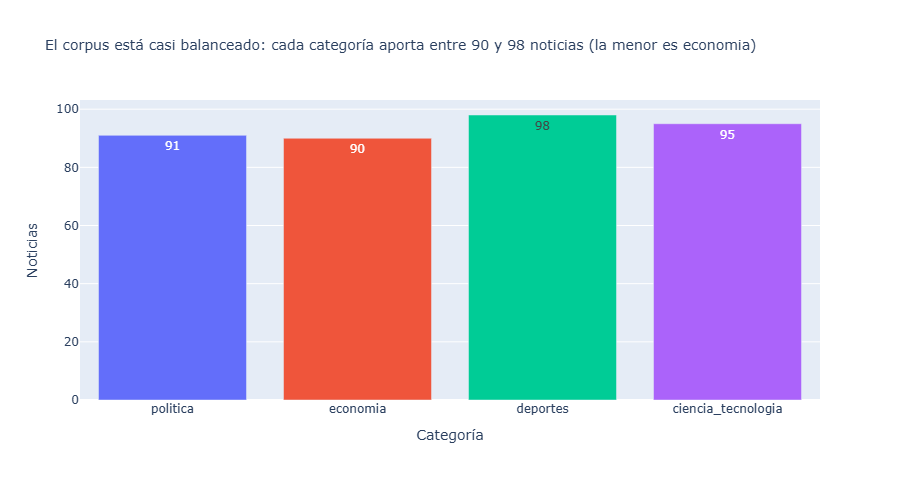

In [11]:
ETIQUETAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]
df["len_titular"] = df["titular"].str.len()
df["fecha_dt"] = pd.to_datetime(df["fecha"], errors="coerce")

conteo = df["etiqueta"].value_counts().reindex(ETIQUETAS).reset_index()
conteo.columns = ["etiqueta", "noticias"]
mn, mx = conteo["noticias"].min(), conteo["noticias"].max()
menor = conteo.loc[conteo["noticias"].idxmin(), "etiqueta"]
fig1 = px.bar(
    conteo, x="etiqueta", y="noticias", text="noticias", color="etiqueta",
    category_orders={"etiqueta": ETIQUETAS},
    title=(f"El corpus está casi balanceado: cada categoría aporta entre {mn} y {mx} noticias "
           f"(la menor es {menor})"),
    labels={"etiqueta": "Categoría", "noticias": "Noticias"},
)
fig1.update_layout(showlegend=False, title_font_size=14)
fig1.show()

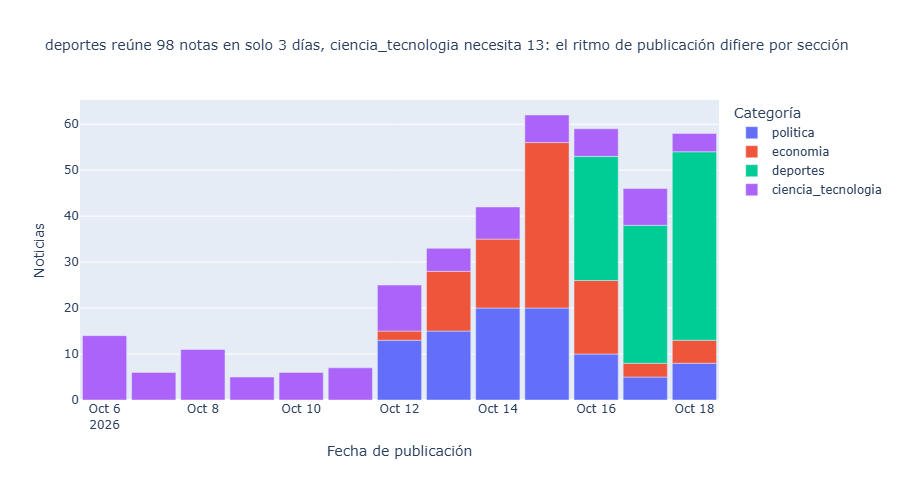

,min,max,size,dias
etiqueta,,,,
ciencia_tecnologia,2026-10-06,2026-10-18,95,13
deportes,2026-10-16,2026-10-18,98,3
economia,2026-10-12,2026-10-18,90,7
politica,2026-10-12,2026-10-18,91,7


In [12]:
por_dia = (df.groupby([df["fecha_dt"].dt.date.rename("fecha"), "etiqueta"])
             .size().reset_index(name="noticias"))
rango = df.groupby("etiqueta")["fecha_dt"].agg(["min", "max", "size"])
rango["dias"] = (rango["max"] - rango["min"]).dt.days + 1
mas_corto, mas_largo = rango["dias"].idxmin(), rango["dias"].idxmax()
fig2 = px.bar(
    por_dia, x="fecha", y="noticias", color="etiqueta",
    category_orders={"etiqueta": ETIQUETAS},
    title=(f"{mas_corto} reúne {rango.loc[mas_corto, 'size']} notas en solo {rango.loc[mas_corto, 'dias']} días, "
           f"{mas_largo} necesita {rango.loc[mas_largo, 'dias']}: el ritmo de publicación difiere por sección"),
    labels={"fecha": "Fecha de publicación", "noticias": "Noticias", "etiqueta": "Categoría"},
)
fig2.update_layout(title_font_size=14, bargap=0.1)
fig2.show()
rango.assign(min=rango["min"].dt.date, max=rango["max"].dt.date)

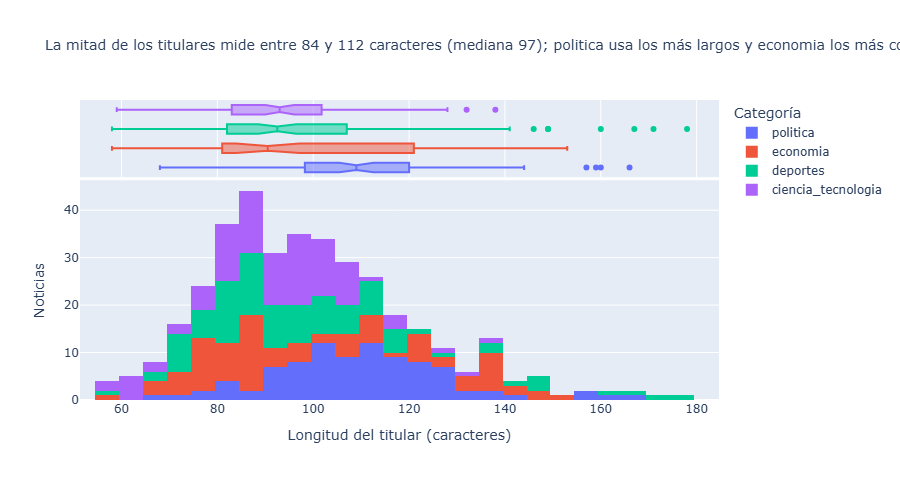

,mediana de caracteres
etiqueta,
economia,90.5
deportes,92.5
ciencia_tecnologia,93.0
politica,109.0


In [13]:
med = df["len_titular"].median()
q1, q3 = df["len_titular"].quantile([0.25, 0.75])
med_cat = df.groupby("etiqueta")["len_titular"].median().sort_values()
fig3 = px.histogram(
    df, x="len_titular", nbins=30, color="etiqueta", marginal="box",
    category_orders={"etiqueta": ETIQUETAS},
    title=(f"La mitad de los titulares mide entre {q1:.0f} y {q3:.0f} caracteres (mediana {med:.0f}); "
           f"{med_cat.index[-1]} usa los más largos y {med_cat.index[0]} los más cortos"),
    labels={"len_titular": "Longitud del titular (caracteres)", "etiqueta": "Categoría"},
)
fig3.update_layout(title_font_size=14, yaxis_title="Noticias")
fig3.show()
med_cat.rename("mediana de caracteres").to_frame()

## 5. Validación: titulares más largos y más cortos
Sirve para comprobar que los extremos del histograma son titulares reales y no errores de extracción (por ejemplo, texto del menú o un titular cortado).

In [14]:
cols = ["len_titular", "etiqueta", "titular"]
print("5 titulares MÁS LARGOS")
display(df.nlargest(5, "len_titular")[cols].reset_index(drop=True))
print("5 titulares MÁS CORTOS")
display(df.nsmallest(5, "len_titular")[cols].reset_index(drop=True))
print(f"Rango observado: {df['len_titular'].min()}–{df['len_titular'].max()} caracteres, "
      f"coherente con los extremos del histograma.")

5 titulares MÁS LARGOS


,len_titular,etiqueta,titular
0,178,deportes,"“El jugador peruano tiene un déficit grande en nutrición y táctica que resuelve a los 20 años, eso en Argentina es a..."
1,171,deportes,El furioso “Que se dedique a administrar” de Guede a Franco Velazco y un Quevedo que reconquistó a Comando Sur: Lo q...
2,167,deportes,“Creo que puedo llegar a un top 3 sin que nadie se quede botado”: Raúl ‘Mono’ Orlandini le responde a El Comercio so...
3,166,politica,"Keiko Fujimori sobre Álvaro Vargas Llosa: “Confío en que su trayectoria, experiencia y compromiso contribuirán a for..."
4,160,deportes,"“El día de mañana me encantaría ver a tantas niñas entrando al automovilismo”: Annia Cillóniz, líder en la categoría..."


5 titulares MÁS CORTOS


,len_titular,etiqueta,titular
0,58,economia,Precio del dólar en Perú: cierre del domingo 18 de octubre
1,58,deportes,"Neymar se rinde ante Lamine Yamal: ""Es el mejor del mundo"""
2,59,ciencia_tecnologia,"Qué es la ""depresión sonriente"" y cómo puedes identificarla"
3,59,ciencia_tecnologia,¿Qué secreto de longevidad atesora una tortuga de 194 años?
4,60,ciencia_tecnologia,Nuevos pasos hacia relojes más precisos aún que los atómicos


Rango observado: 58–178 caracteres, coherente con los extremos del histograma.


## 6. Exportación de `datos/noticias.csv`

In [15]:
COLUMNAS = ["titular", "bajada", "medio", "seccion_original", "url", "fecha", "etiqueta"]
final = df.sort_values(["etiqueta", "fecha"], ascending=[True, False])[COLUMNAS].reset_index(drop=True)

assert final["url"].is_unique and (final["titular"] != "").all()
assert set(final["etiqueta"]) == set(ETIQUETAS)
final.to_csv(DATOS / "noticias.csv", index=False, encoding="utf-8")

print("df.shape:", final.shape)
print("Bajadas vacías:", int((final["bajada"] == "").sum()))
print("Todas las URLs respondieron HTTP 200 al descargarlas:",
      bool((df_raw.set_index("url").loc[final["url"], "status"] == 200).all()))
final.head()

df.shape: (374, 7)
Bajadas vacías: 0
Todas las URLs respondieron HTTP 200 al descargarlas: True


,titular,bajada,medio,seccion_original,url,fecha,etiqueta
0,Tesla presenta un Roadster capaz de ‘volar’ y en las redes sociales lo reciben con memes,El nuevo vehículo de Elon Musk combina tecnología de SpaceX. Durante las pruebas realizó varias piruetas en el aire ...,El Comercio,tecnologia/actualidad,https://elcomercio.pe/tecnologia/actualidad/tesla-presenta-un-roadster-capaz-de-volar-y-en-las-redes-sociales-lo-rec...,2026-10-18,ciencia_tecnologia
1,Alemania investiga una presunta agresión sexual con un robot contra joven de 16 años,La agresión ocurrió en Colonia y fue transmitida en directo en redes sociales. El robot fue encontrado en la maleter...,El Comercio,tecnologia/robotica,https://elcomercio.pe/tecnologia/robotica/alemania-investiga-una-presunta-agresion-sexual-con-un-robot-contra-joven-...,2026-10-18,ciencia_tecnologia
2,Intel en Latinoamérica: “Los gobiernos deben crear condiciones o reglas para un uso saludable de la IA”,João Bortone asumió la dirección de la firma estadounidense en nuestra región. Señala que “estamos en un momento atí...,El Comercio,tecnologia/actualidad,https://elcomercio.pe/tecnologia/actualidad/intel-en-latinoamerica-los-gobiernos-deben-crear-condiciones-o-reglas-pa...,2026-10-18,ciencia_tecnologia
3,Padre de la IA y otros 224 científicos piden “cambios inmediatos” para su desarrollo y despliegue,"La carta abierta, que además de Yoshua Bengio incluye a especialistas en IA y ciberseguridad, remarcó incidentes don...",El Comercio,tecnologia/inteligencia-artificial,https://elcomercio.pe/tecnologia/inteligencia-artificial/padre-de-la-ia-y-otros-224-cientificos-piden-cambios-inmedi...,2026-10-18,ciencia_tecnologia
4,Descubren en los Andes peruanos una nueva flor y la bautizan en honor a Lionel Messi,Un grupo de investigadores en botánica descubrió una flor que crece en las laderas rocosas de la sierra peruana y po...,El Comercio,tecnologia/ciencias,https://elcomercio.pe/tecnologia/ciencias/salvia-messii-descubren-en-los-andes-peruanos-una-nueva-flor-y-la-bautizan...,2026-10-17,ciencia_tecnologia
